In [1]:
import numpy, scipy, pandas, sklearn, torch
print(numpy.__version__, scipy.__version__, pandas.__version__, torch.__version__)
print("MPS available:", torch.backends.mps.is_available())

2.4.4 1.16.3 3.0.2 2.9.0
MPS available: True


In [2]:
"""
data.py - corpus cleaning, tokenization, splits, vocab, batching.
Run from the "Assignment 1" folder:  python src/data.py
"""
import re, json, random
from collections import Counter
from pathlib import Path

import torch
from torch.utils.data import Dataset, DataLoader

SEED = 42
CORPUS_PATH = Path("data/sustainability_reports_corpus.txt")
PROC_DIR = Path("data/processed")
BLOCK_SIZE = 64          # context length (same for all neural models)
MIN_FREQ = 3             # word must appear >= 3 times in TRAIN to be in vocab
MAX_VOCAB = 10000        # cap incl. special tokens
SPECIALS = ["<pad>", "<unk>", "<eos>"]   # ids 0, 1, 2
PAD, UNK, EOS = 0, 1, 2

MARKER_RE = re.compile(r"<<<REPORT_START[^>]*>>>")
TOKEN_RE = re.compile(r"<num>|[a-z]+(?:['\u2019-][a-z]+)*|[.,;:!?()%]")


# ---------- cleaning / tokenization ----------
def split_reports(text):
    """Split the raw file into one string per report (using the markers)."""
    parts = MARKER_RE.split(text)
    return [p.strip() for p in parts if p.strip()]


def tokenize_paragraph(par):
    par = par.lower()
    par = par.replace("\u2019", "'")
    par = re.sub(r"[\u2022\u2013\u2014\u25cf\u25aa]", " ", par)     # bullets, dashes
    par = re.sub(r"\d[\d,]*\.?\d*", " <num> ", par)                 # numbers -> <num>
    return TOKEN_RE.findall(par)


def tokenize_report(report):
    """Paragraph (blank-line separated) -> tokens ending with <eos>."""
    tokens = []
    for par in re.split(r"\n\s*\n", report):
        toks = tokenize_paragraph(par)
        if len(toks) >= 3:                 # drop tiny fragments (page numbers etc.)
            tokens.extend(toks + ["<eos>"])
    return tokens


# ---------- splits (contiguous, per report, so no random sentence leakage) ----------
def split_tokens(reports_tokens, frac=(0.8, 0.1, 0.1)):
    train, val, test = [], [], []
    for toks in reports_tokens:
        n = len(toks)
        a, b = int(n * frac[0]), int(n * (frac[0] + frac[1]))
        train += toks[:a]; val += toks[a:b]; test += toks[b:]
    return train, val, test


# ---------- vocab (TRAIN ONLY) ----------
def build_vocab(train_tokens):
    counts = Counter(t for t in train_tokens if t not in SPECIALS)
    words = [w for w, c in counts.most_common() if c >= MIN_FREQ]
    words = words[: MAX_VOCAB - len(SPECIALS)]
    itos = SPECIALS + words
    stoi = {w: i for i, w in enumerate(itos)}
    return itos, stoi


def encode(tokens, stoi):
    return [stoi.get(t, UNK) for t in tokens]


# ---------- windows / dataloaders ----------
class WindowDataset(Dataset):
    """Non-overlapping windows of BLOCK_SIZE+1 ids -> (input, target) shifted by one.
    Last window is padded with <pad>; the loss must use ignore_index=PAD."""
    def __init__(self, ids, block_size=BLOCK_SIZE):
        self.windows = []
        step = block_size
        for s in range(0, len(ids) - 1, step):
            w = ids[s : s + block_size + 1]
            if len(w) < 2:
                continue
            w = w + [PAD] * (block_size + 1 - len(w))
            self.windows.append(w)
        self.windows = torch.tensor(self.windows, dtype=torch.long)

    def __len__(self):
        return len(self.windows)

    def __getitem__(self, i):
        w = self.windows[i]
        return w[:-1], w[1:]


def prepare(force=False):
    """Run the full pipeline once and cache to data/processed/."""
    PROC_DIR.mkdir(parents=True, exist_ok=True)
    cache = PROC_DIR / "ids.pt"
    if cache.exists() and not force:
        return torch.load(cache), json.loads((PROC_DIR / "vocab.json").read_text())

    text = CORPUS_PATH.read_text(encoding="utf-8", errors="ignore")
    reports = split_reports(text)
    reports_tokens = [tokenize_report(r) for r in reports]
    train_t, val_t, test_t = split_tokens(reports_tokens)
    itos, stoi = build_vocab(train_t)

    data = {
        "train": encode(train_t, stoi),
        "val": encode(val_t, stoi),
        "test": encode(test_t, stoi),
        "n_reports": len(reports),
    }
    torch.save(data, cache)
    (PROC_DIR / "vocab.json").write_text(json.dumps(itos))
    return data, itos


def get_loaders(batch_size=64, block_size=BLOCK_SIZE):
    data, itos = prepare()
    g = torch.Generator().manual_seed(SEED)
    train = DataLoader(WindowDataset(data["train"], block_size), batch_size, shuffle=True, generator=g)
    val = DataLoader(WindowDataset(data["val"], block_size), batch_size)
    test = DataLoader(WindowDataset(data["test"], block_size), batch_size)
    return train, val, test, itos


# ---------- stats for the report ----------
if __name__ == "__main__":
    random.seed(SEED); torch.manual_seed(SEED)
    data, itos = prepare(force=True)
    print(f"Reports found      : {data['n_reports']}")
    for k in ("train", "val", "test"):
        ids = data[k]
        unk = sum(1 for i in ids if i == UNK) / max(1, len(ids))
        print(f"{k:5s} tokens: {len(ids):>9,d}   <unk> rate: {unk:.2%}")
    print(f"Vocab size         : {len(itos):,d} (min_freq={MIN_FREQ}, cap={MAX_VOCAB})")
    print("Most common        :", itos[3:23])
    print("Sample (train)     :", " ".join(itos[i] for i in data["train"][1000:1060]))

Reports found      : 9
train tokens:   283,078   <unk> rate: 2.59%
val   tokens:    35,384   <unk> rate: 5.12%
test  tokens:    35,388   <unk> rate: 4.53%
Vocab size         : 5,758 (min_freq=3, cap=10000)
Most common        : ['and', ',', '.', 'the', 'to', '<num>', 'of', 'in', 'our', 'a', 'for', 'we', 'with', 'as', 'on', ')', '(', 'by', 'are', 'is']
Sample (train)     : risks executive resource compensation committee reporting scope gri <num> <num> <num> <num> our report provides information on sembcorp and its subsidiaries and covers the period from january <num> to december <num> <num> it excludes operations , joint ventures , partnerships and associates where sembcorp does not have control , with the exception of greenhouse gas ( ghg ) emissions data


,tag,val_ppl,test_ppl,best_epoch,epochs_run,params,train_s,s_per_epoch
0,lstm_lr1e-3,114.15,120.89,92.0,100.0,2422198.0,865.93,8.66
1,lstm_lr3e-3,114.29,122.73,37.0,45.0,2422198.0,346.85,7.71
2,lstm_s42,128.21,132.62,40.0,40.0,2422198.0,349.50,8.74
3,ngram,142.02,144.28,NaN,NaN,NaN,0.27,NaN
4,rnn_lr1e-3,129.45,134.58,49.0,57.0,2147254.0,297.02,5.21
5,rnn_lr3e-3,137.19,144.85,26.0,34.0,2147254.0,196.46,5.78
6,transformer_lr1e-3,120.87,127.43,100.0,100.0,1348670.0,539.82,5.40
7,transformer_lr3e-3_long,106.80,113.59,105.0,113.0,1348670.0,729.24,6.45
8,transformer_lr3e-3,108.08,115.30,100.0,100.0,1348670.0,982.45,9.82


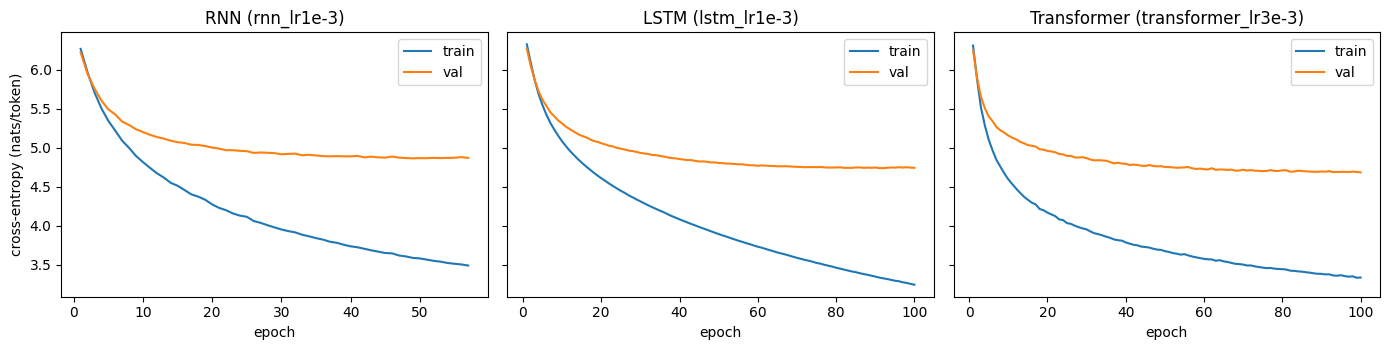

In [4]:
import json, glob, pandas as pd, matplotlib.pyplot as plt

rows = []
for f in sorted(glob.glob("results/*_result.json")):
    r = json.load(open(f))
    ep = r.get("epochs_run")
    rows.append({
        "tag": r["tag"],
        "val_ppl": r.get("best_val_ppl", r.get("val_ppl")),
        "test_ppl": r["test_ppl"],
        "best_epoch": r.get("best_epoch"), "epochs_run": ep,
        "params": r.get("params_total"),
        "train_s": r["train_time_s"],
        "s_per_epoch": r["train_time_s"] / ep if ep else None,
    })
df = pd.DataFrame(rows).round(2)
display(df)

# curves: edit these to your chosen (lowest val_ppl) run per family
chosen = {"RNN": "rnn_lr1e-3", "LSTM": "lstm_lr1e-3", "Transformer": "transformer_lr3e-3"}
fig, axs = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
for ax, (name, tag) in zip(axs, chosen.items()):
    d = pd.read_csv(f"results/{tag}_log.csv")
    ax.plot(d.epoch, d.train_loss, label="train"); ax.plot(d.epoch, d.val_loss, label="val")
    ax.set_title(f"{name} ({tag})"); ax.set_xlabel("epoch"); ax.legend()
axs[0].set_ylabel("cross-entropy (nats/token)")
plt.tight_layout(); plt.savefig("results/loss_curves.png", dpi=200); plt.show()

In [ ]:
import pandas as pd, matplotlib.pyplot as plt

def curves(ax, tag, title):
    d = pd.read_csv(f"results/{tag}_log.csv")
    ax.plot(d.epoch, d.train_loss, label="train"); ax.plot(d.epoch, d.val_loss, label="val")
    ax.set_title(title); ax.set_xlabel("epoch"); ax.legend()

for fname, runs in {
    "fig_part1_curves": {"RNN": "rnn_lr1e-3", "LSTM": "lstm_lr3e-3", "Transformer": "transformer_lr3e-3"},
    "fig_part2_curves": {"random (trainable)": "lstm_lr3e-3", "own Skip-gram (frozen)": "lstm_sgns_frozen",
                         "GloVe (frozen)": "lstm_glove_frozen"}}.items():
    fig, axs = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
    for ax, (n, t) in zip(axs, runs.items()): curves(ax, t, n)
    axs[0].set_ylabel("cross-entropy (nats/token)")
    plt.tight_layout(); plt.savefig(f"results/{fname}.png", dpi=200); plt.show()

g = pd.read_csv("results/classify_summary.csv")
models = ["RNN", "LSTM", "Transformer", "LSTM+SGNS(frozen)", "LSTM+GloVe(frozen)"]
fig, ax = plt.subplots(figsize=(10, 4)); w = 0.25
for k, p in enumerate(["last", "mean", "embmean"]):
    d = g[g.pooling == p].set_index("model").loc[models]
    ax.bar([i + (k - 1) * w for i in range(len(models))], d.f1_mean, w, label=p,
           yerr=[d.f1_mean - d.f1_min, d.f1_max - d.f1_mean], capsize=3)
ax.axhline(g[g.model == "TF-IDF (no LM)"].f1_mean.iloc[0], ls="--", color="k", label="TF-IDF baseline")
ax.set_xticks(range(len(models))); ax.set_xticklabels(models, rotation=15)
ax.set_ylabel("test macro-F1 (mean, min-max)"); ax.set_ylim(0.6, 0.95); ax.legend()
plt.tight_layout(); plt.savefig("results/fig_part3_f1.png", dpi=200); plt.show()